# Réseau Neuronal Analogique — Caractéristiques & Simulation

Ce notebook contient :
1. Les **courbes de caractéristiques** des blocs élémentaires (entrée, neurone, synapses)
2. Un **réseau multicouche configurable** : vous définissez la taille de chaque couche et les poids, et obtenez la sortie

## 0. Imports & Configuration

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11

In [35]:
# ── Fichiers CSV ──────────────────────────────────────────
INPUT_CSV   = "input_min_conso.csv"
NEURON_CSV  = "neuron.csv"
SYN_EXC_CSV = "excitation20.csv"
SYN_INH_CSV = "inhibition20.csv"

USE_ZERO_BELOW_NEURON_RANGE = False
FREQ_MERGE_TOL_HZ = 1000.0

## 1. Fonctions de base (lecture CSV + interpolation)

In [36]:
def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if "Parameter" not in df.columns:
        raise ValueError(f"{csv_path}: colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ["Parameter", "Unnamed: 1"]]

    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df["Parameter"] == row_name, data_cols]
        if row.empty:
            raise ValueError(f"Ligne '{row_name}' introuvable dans {csv_path}")
        values = pd.to_numeric(row.iloc[0], errors="coerce").to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            bad_idx = np.where(np.isnan(values))[0]
            raise ValueError(f"Ligne '{row_name}' contient des NaN aux indices {bad_idx[:10]}")
        return values
    return get_row


def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    stacked = np.vstack(rows)
    mask = np.all(np.isfinite(stacked), axis=0)
    return [r[mask] for r in rows], mask


def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])


def interp2d_bilinear(x, y, x_axis, y_axis, z_grid):
    x = float(np.clip(x, x_axis[0], x_axis[-1]))
    y = float(np.clip(y, y_axis[0], y_axis[-1]))
    ix = int(np.clip(np.searchsorted(x_axis, x) - 1, 0, len(x_axis) - 2))
    iy = int(np.clip(np.searchsorted(y_axis, y) - 1, 0, len(y_axis) - 2))
    x1, x2 = x_axis[ix], x_axis[ix + 1]
    y1, y2 = y_axis[iy], y_axis[iy + 1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[ix,iy]*(1-tx)*(1-ty) + z_grid[ix+1,iy]*tx*(1-ty)
          + z_grid[ix,iy+1]*(1-tx)*ty   + z_grid[ix+1,iy+1]*tx*ty)


def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    x_m, y_m = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(x_m)
    return x_m[o], y_m[o]


def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])


def snap_to_axis(values, axis):
    values = np.asarray(values, float)
    return np.array([axis[np.argmin(np.abs(axis - v))] for v in values])


def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = map(lambda a: np.asarray(a, float), [W_all, F_all, Y_all])
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError(f"Point manquant W={w}, F={f}")
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

## 2. Chargement des modèles

In [37]:
# Bloc d'entrée
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp("Vex"), inp("Fspikes")
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

def input_f_of_v(Vin_V):
    return interp_clip(Vin_V, INPUT_V_AXIS, INPUT_F_AXIS)

# Neurone
neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro("Iex"), neuro("Fspikes")
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

def neuron_f_of_i(Iin_A):
    Iin_A = np.asarray(Iin_A, float)
    out = interp_clip(Iin_A, NEURON_I_AXIS, NEURON_F_AXIS)
    if USE_ZERO_BELOW_NEURON_RANGE:
        out = np.where(Iin_A < NEURON_I_AXIS[0], 0.0, out)
    return out

# Synapse excitatrice
syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), mask_exc = get_clean_rows(syn_exc, ["W2", "Fpre", "Ipost"])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

def isyn_exc(Fpre_Hz, Wexc_um):
    return interp2d_bilinear(Wexc_um, Fpre_Hz, W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID)

# Synapse inhibitrice
syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), mask_inh = get_clean_rows(syn_inh, ["W2", "Fpre", "Ipost"])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

def isyn_inh(Fpre_Hz, Winh_um):
    return interp2d_bilinear(Winh_um, Fpre_Hz, W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID)

print("✓ Tous les modèles sont chargés.")

✓ Tous les modèles sont chargés.


## 3. Courbes de caractéristiques

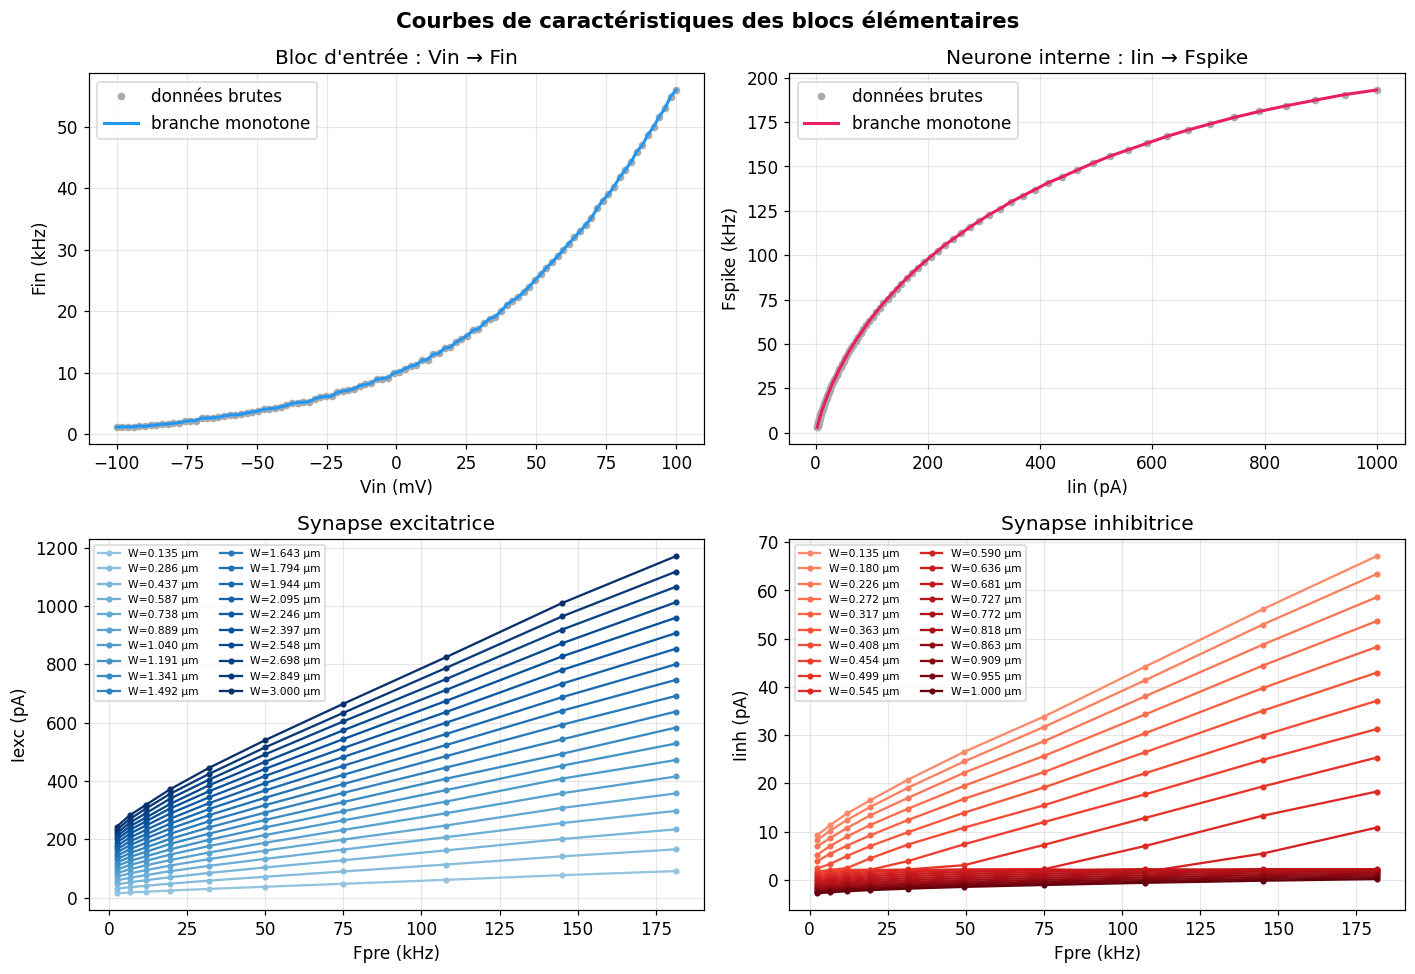

In [38]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
fig.suptitle("Courbes de caractéristiques des blocs élémentaires", fontsize=14, fontweight='bold')

# ── Bloc d'entrée : Vin → Fin ─────────────────────────────
ax = axs[0, 0]
ax.plot(VEX_IN * 1e3, FSPIKES_IN * 1e-3, 'o', color='#aaa', ms=4, label="données brutes")
ax.plot(INPUT_V_AXIS * 1e3, INPUT_F_AXIS * 1e-3, '-', color='#2196F3', lw=2, label="branche monotone")
ax.set_xlabel("Vin (mV)")
ax.set_ylabel("Fin (kHz)")
ax.set_title("Bloc d'entrée : Vin → Fin")
ax.grid(True, alpha=0.3)
ax.legend()

# ── Neurone : Iin → Fspike ────────────────────────────────
ax = axs[0, 1]
ax.plot(IEX_NEURO * 1e12, FSPIKES_NEURO * 1e-3, 'o', color='#aaa', ms=4, label="données brutes")
ax.plot(NEURON_I_AXIS * 1e12, NEURON_F_AXIS * 1e-3, '-', color='#E91E63', lw=2, label="branche monotone")
ax.set_xlabel("Iin (pA)")
ax.set_ylabel("Fspike (kHz)")
ax.set_title("Neurone interne : Iin → Fspike")
ax.grid(True, alpha=0.3)
ax.legend()

# ── Synapse excitatrice : Fpre → Iexc ────────────────────
ax = axs[1, 0]
cmap_exc = plt.cm.Blues(np.linspace(0.4, 1.0, len(W_EXC_AXIS)))
for i, w in enumerate(W_EXC_AXIS):
    ax.plot(F_EXC_AXIS * 1e-3, IPOST_EXC_GRID[i] * 1e12, 'o-',
            color=cmap_exc[i], lw=1.5, ms=3, label=f"W={w:.3f} µm")
ax.set_xlabel("Fpre (kHz)")
ax.set_ylabel("Iexc (pA)")
ax.set_title("Synapse excitatrice")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7, ncol=2)

# ── Synapse inhibitrice : Fpre → Iinh ────────────────────
ax = axs[1, 1]
cmap_inh = plt.cm.Reds(np.linspace(0.4, 1.0, len(W_INH_AXIS)))
for i, w in enumerate(W_INH_AXIS):
    ax.plot(F_INH_AXIS * 1e-3, IPOST_INH_GRID[i] * 1e12, 'o-',
            color=cmap_inh[i], lw=1.5, ms=3, label=f"W={w:.3f} µm")
ax.set_xlabel("Fpre (kHz)")
ax.set_ylabel("Iinh (pA)")
ax.set_title("Synapse inhibitrice")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=7, ncol=2)

plt.tight_layout()
plt.show()

## 4. Couche élémentaire (forward)

In [39]:
def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """
    Propagation d'une couche.

    Entrées
    -------
    Fin_vec_Hz      : (N,)    fréquences pre-synaptiques [Hz]
    sign_matrix     : (N, M)  +1 excitateur, -1 inhibiteur
    width_matrix_um : (N, M)  largeur des synapses [µm]

    Sorties
    -------
    Fout_vec_Hz : (M,)  fréquences post-synaptiques [Hz]
    Iconn_mat_A : (N, M) courants signés [A]
    Itot_vec_A  : (M,)  courant total par neurone de sortie [A]
    """
    N = len(Fin_vec_Hz)
    M = sign_matrix.shape[1]
    Iconn_mat_A = np.zeros((N, M))

    for i in range(N):
        for j in range(M):
            s, w = sign_matrix[i, j], width_matrix_um[i, j]
            if s == 1:
                Iconn_mat_A[i, j] = float(isyn_exc(Fin_vec_Hz[i], w))
            elif s == -1:
                Iconn_mat_A[i, j] = -float(isyn_inh(Fin_vec_Hz[i], w))
            else:
                raise ValueError("sign_matrix doit contenir +1 ou -1 uniquement")

    Itot_vec_A  = np.sum(Iconn_mat_A, axis=0)
    Fout_vec_Hz = np.array([float(neuron_f_of_i(itot)) for itot in Itot_vec_A])
    return Fout_vec_Hz, Iconn_mat_A, Itot_vec_A

## 5. Réseau multicouche configurable

Définissez ici la **topologie** et les **poids** du réseau, puis exécutez la cellule suivante.

In [40]:
# ╔══════════════════════════════════════════════════════════════╗
# ║              CONFIGURATION DU RÉSEAU                        ║
# ╠══════════════════════════════════════════════════════════════╣
# ║  Modifiez les valeurs ci-dessous puis exécutez la cellule.  ║
# ╚══════════════════════════════════════════════════════════════╝

# ── Entrées : tensions Vin (en V) ────────────────────────────
Vin_V = np.array([-50e-3, -50e-3])          # une valeur par neurone d'entrée

# ── Topologie ────────────────────────────────────────────────
# layer_sizes = [N_in, couche1, couche2, ..., N_out]
# Exemple [2, 2, 2, 2] = 2 entrées → couche(2) → couche(2) → 2 sorties
layer_sizes = [2, 4, 4, 2]

# ── Poids par couche ─────────────────────────────────────────
# Un élément par couche de connexion (len(layer_sizes) - 1 éléments).
# Chaque élément est un dict avec :
#   'signs'  : matrice (N_in_couche, N_out_couche) de +1 / -1
#   'widths' : matrice (N_in_couche, N_out_couche) de largeurs en µm
#
# Largeurs disponibles (excitation) : W_EXC_AXIS
# Largeurs disponibles (inhibition) : W_INH_AXIS

layers_config = [
    {
        'signs':  np.array([[ 1,  1,  1,  1],
                            [-1, -1,  1,  1]]),
        'widths': np.array([[3.    , 0.4366, 1.794 , 2.548 ],
                            [0.6358, 0.4082, 0.7382, 0.135 ]]),
    },
    {
        'signs':  np.array([[-1, -1,  1,  1],
                            [-1, -1, -1 ,-1],
                            [ 1,  1, -1, -1],
                            [ 1, -1,  1,  1]]),
        'widths': np.array([[0.135 , 0.135 , 0.2858, 1.341 ],
                            [0.5903, 0.135 , 0.135 , 0.8634],
                            [0.4366, 1.191 , 0.2716, 0.6358],
                            [2.246 , 0.8634, 1.191 , 1.04  ]]),
    },
    {
        'signs':  np.array([[-1 , 1],
                            [ 1, -1],
                            [-1, -1],
                            [-1, -1]]),
        'widths': np.array([[0.135 , 0.2858],
                            [0.4366, 0.2716],
                            [0.2716, 0.135 ],
                            [0.1805, 0.1805]]),
    },
]

print(f"Réseau configuré : {layer_sizes}")
print(f"Nombre de couches de connexion : {len(layers_config)}")
assert len(layers_config) == len(layer_sizes) - 1, \
    f"Il faut {len(layer_sizes)-1} couches de config, pas {len(layers_config)}"
print("✓ Configuration valide.")

Réseau configuré : [2, 4, 4, 2]
Nombre de couches de connexion : 3
✓ Configuration valide.


### Propagation & visualisation

In [41]:
# ── Propagation ───────────────────────────────────────────────
assert len(Vin_V) == layer_sizes[0], \
    f"Vin_V a {len(Vin_V)} entrées mais layer_sizes[0]={layer_sizes[0]}"

# Conversion tensions → fréquences (bloc d'entrée)
current_F = np.array([float(input_f_of_v(v)) for v in Vin_V])

# Historique pour visualisation
history_F      = [current_F.copy()]   # fréquences après chaque couche
history_Iconn  = []                   # courants par couche
history_Itot   = []                   # courant total par couche

for k, cfg in enumerate(layers_config):
    signs  = np.asarray(cfg['signs'],  int)
    widths = np.asarray(cfg['widths'], float)

    assert signs.shape  == (len(current_F), layer_sizes[k+1]), \
        f"Couche {k}: signs.shape={signs.shape}, attendu ({len(current_F)}, {layer_sizes[k+1]})"
    assert widths.shape == signs.shape, \
        f"Couche {k}: widths.shape={widths.shape} != signs.shape={signs.shape}"

    current_F, Iconn, Itot = layer_forward(current_F, signs, widths)
    history_F.append(current_F.copy())
    history_Iconn.append(Iconn)
    history_Itot.append(Itot)

# ── Résumé texte ──────────────────────────────────────────────
print("=" * 52)
print(f"  Réseau : {layer_sizes}")
print("=" * 52)
print(f"  Vin  (mV)  = {Vin_V * 1e3}")
print(f"  Fin  (kHz) = {history_F[0] * 1e-3}")
for k in range(len(layers_config)):
    print(f"  Couche {k}→{k+1} :")
    print(f"    Itot (pA)   = {history_Itot[k] * 1e12}")
    print(f"    Fout (kHz)  = {history_F[k+1] * 1e-3}")
print("=" * 52)
print(f"  SORTIE FINALE (kHz) = {history_F[-1] * 1e-3}")
print(f"  Classe prédite      = {int(np.argmax(history_F[-1]))}")
print("=" * 52)

  Réseau : [2, 4, 4, 2]
  Vin  (mV)  = [-50. -50.]
  Fin  (kHz) = [3.68707882 3.68707882]
  Couche 0→1 :
    Itot (pA)   = [254.85511529  45.47251316 236.62350047 235.64326125]
    Fout (kHz)  = [111.30216874  37.60442413 107.2337751  107.01672213]
  Couche 1→2 :
    Itot (pA)   = [747.43871309 298.69778313 426.19392936 742.00380129]
    Fout (kHz)  = [177.73107815 120.68371738 142.41115406 177.28691023]
  Couche 2→3 :
    Itot (pA)   = [3.68193897 7.87979667]
    Fout (kHz)  = [4.21835692 9.17224681]
  SORTIE FINALE (kHz) = [4.21835692 9.17224681]
  Classe prédite      = 1


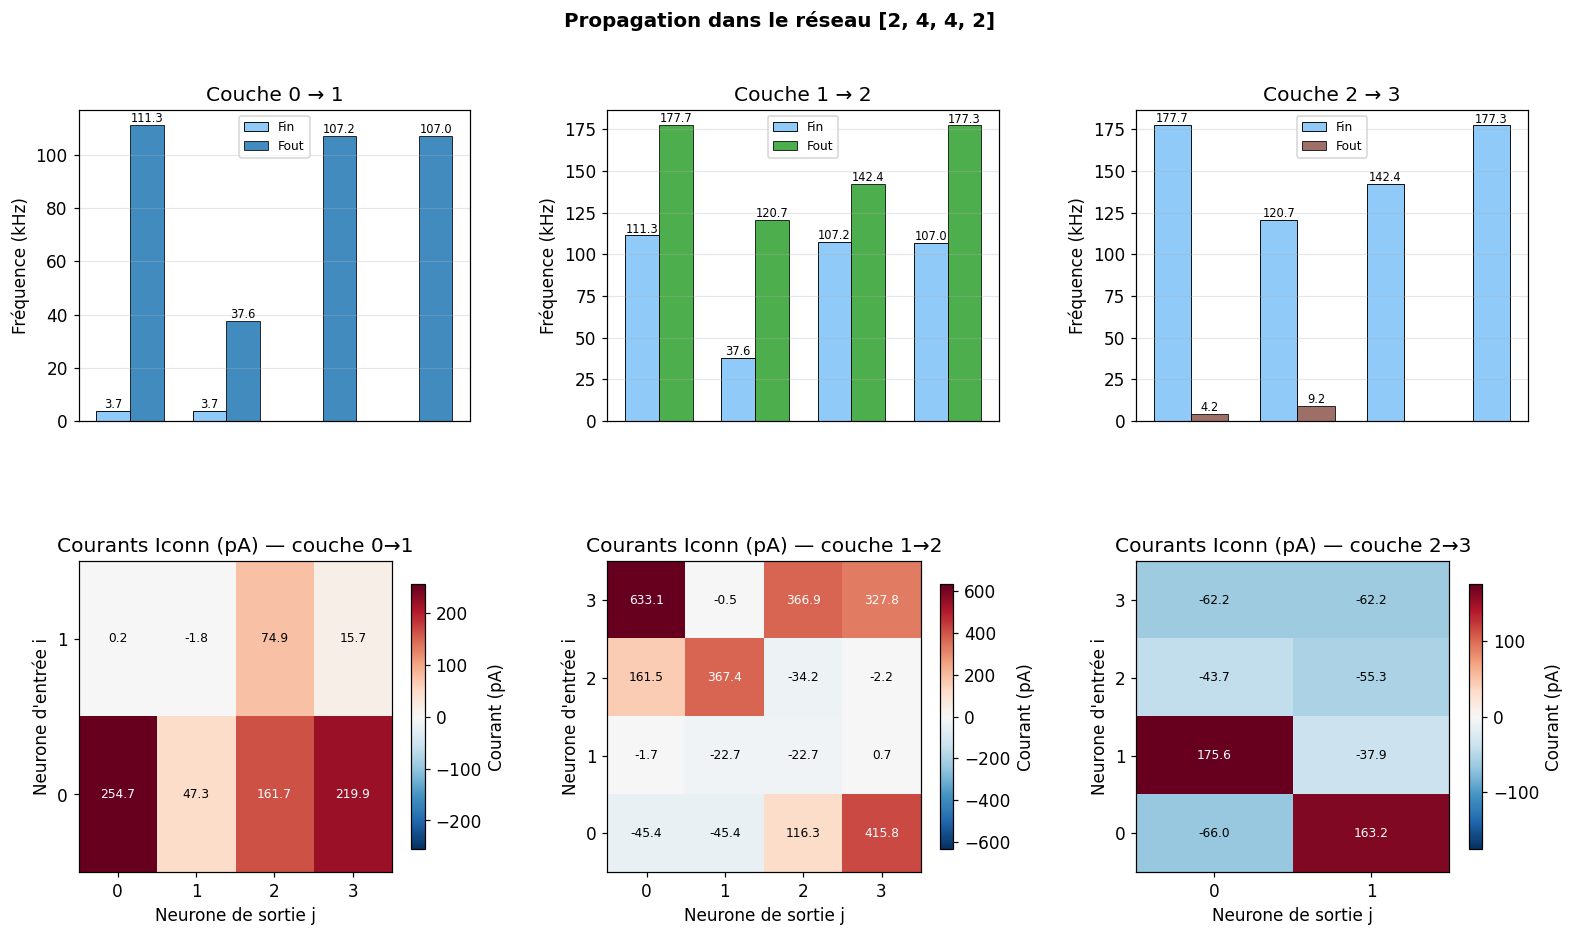

In [42]:
# ── Visualisation du réseau ───────────────────────────────────
n_layers_total = len(layer_sizes)   # nombre de couches de neurones (y compris entrée)
n_conn_layers  = len(layers_config)

fig = plt.figure(figsize=(5 * n_conn_layers + 2, 9))
fig.suptitle(f"Propagation dans le réseau {layer_sizes}", fontsize=13, fontweight='bold')

gs = gridspec.GridSpec(2, n_conn_layers, figure=fig, hspace=0.45, wspace=0.35)

colors_layers = plt.cm.tab10(np.linspace(0, 0.5, n_conn_layers))

for k in range(n_conn_layers):
    Fin_k  = history_F[k]
    Fout_k = history_F[k + 1]
    Iconn  = history_Iconn[k]
    Itot   = history_Itot[k]
    N, M   = Iconn.shape
    color  = colors_layers[k]

    # ── Haut : fréquences entrée & sortie de la couche ────
    ax_top = fig.add_subplot(gs[0, k])
    x_in  = np.arange(N)
    x_out = np.arange(M)
    width = 0.35
    b1 = ax_top.bar(x_in - width/2, Fin_k * 1e-3,  width, label="Fin",  color='#90CAF9', edgecolor='k', linewidth=0.6)
    b2 = ax_top.bar(x_out + width/2, Fout_k * 1e-3, width, label="Fout", color=color,     edgecolor='k', linewidth=0.6, alpha=0.85)
    ax_top.set_title(f"Couche {k} → {k+1}")
    ax_top.set_ylabel("Fréquence (kHz)")
    ax_top.set_xticks([])
    ax_top.legend(fontsize=8)
    ax_top.grid(True, axis='y', alpha=0.3)

    for bar, val in zip(b1, Fin_k * 1e-3):
        ax_top.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f"{val:.1f}", ha='center', va='bottom', fontsize=7.5)
    for bar, val in zip(b2, Fout_k * 1e-3):
        ax_top.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f"{val:.1f}", ha='center', va='bottom', fontsize=7.5)

    # ── Bas : matrice des courants signés ─────────────────
    ax_bot = fig.add_subplot(gs[1, k])
    vmax   = np.max(np.abs(Iconn)) * 1e12
    im = ax_bot.imshow(
        Iconn * 1e12, aspect='auto', origin='lower',
        cmap='RdBu_r', vmin=-vmax if vmax > 0 else -1, vmax=vmax if vmax > 0 else 1
    )
    plt.colorbar(im, ax=ax_bot, label="Courant (pA)", shrink=0.85)
    ax_bot.set_xlabel("Neurone de sortie j")
    ax_bot.set_ylabel("Neurone d'entrée i")
    ax_bot.set_title(f"Courants Iconn (pA) — couche {k}→{k+1}")
    ax_bot.set_xticks(range(M))
    ax_bot.set_yticks(range(N))

    # Annoter les valeurs dans chaque cellule
    for i in range(N):
        for j in range(M):
            ax_bot.text(j, i, f"{Iconn[i,j]*1e12:.1f}",
                        ha='center', va='center', fontsize=8,
                        color='white' if abs(Iconn[i,j]*1e12) > vmax*0.5 else 'black')

plt.show()

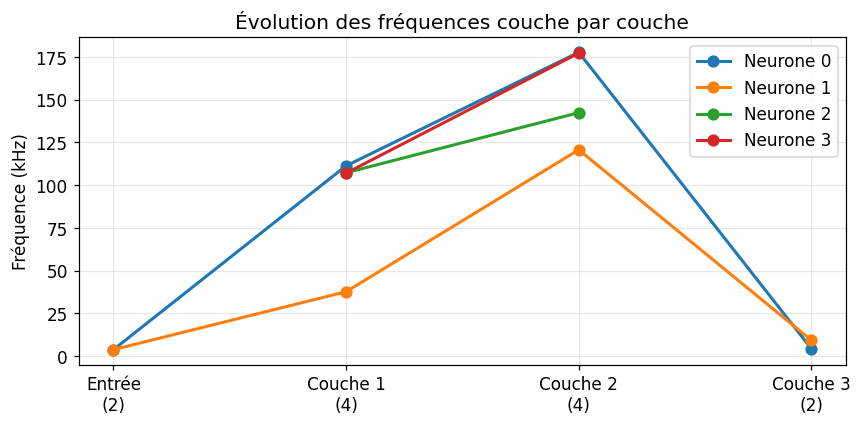

In [43]:
# ── Vue synthétique : évolution des fréquences couche par couche ──
fig, ax = plt.subplots(figsize=(8, 4))

# Une courbe par neurone (on suit sa fréquence de couche en couche)
n_max_neurons = max(layer_sizes)
x_labels = [f"Entrée\n({layer_sizes[0]})"] + \
           [f"Couche {k+1}\n({layer_sizes[k+1]})" for k in range(n_conn_layers)]

# Pad chaque vecteur à n_max_neurons pour tracer proprement
for neuron_idx in range(n_max_neurons):
    xs, ys = [], []
    for layer_idx, F_vec in enumerate(history_F):
        if neuron_idx < len(F_vec):
            xs.append(layer_idx)
            ys.append(F_vec[neuron_idx] * 1e-3)
    ax.plot(xs, ys, 'o-', lw=2, ms=7, label=f"Neurone {neuron_idx}")

ax.set_xticks(range(n_layers_total))
ax.set_xticklabels(x_labels)
ax.set_ylabel("Fréquence (kHz)")
ax.set_title("Évolution des fréquences couche par couche")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Calcul de la decision map (60×60 = 3600 points)...
✓ Terminé.


/tmp/ipykernel_1542250/2229838315.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_dec  = plt.cm.get_cmap('tab10', n_classes)


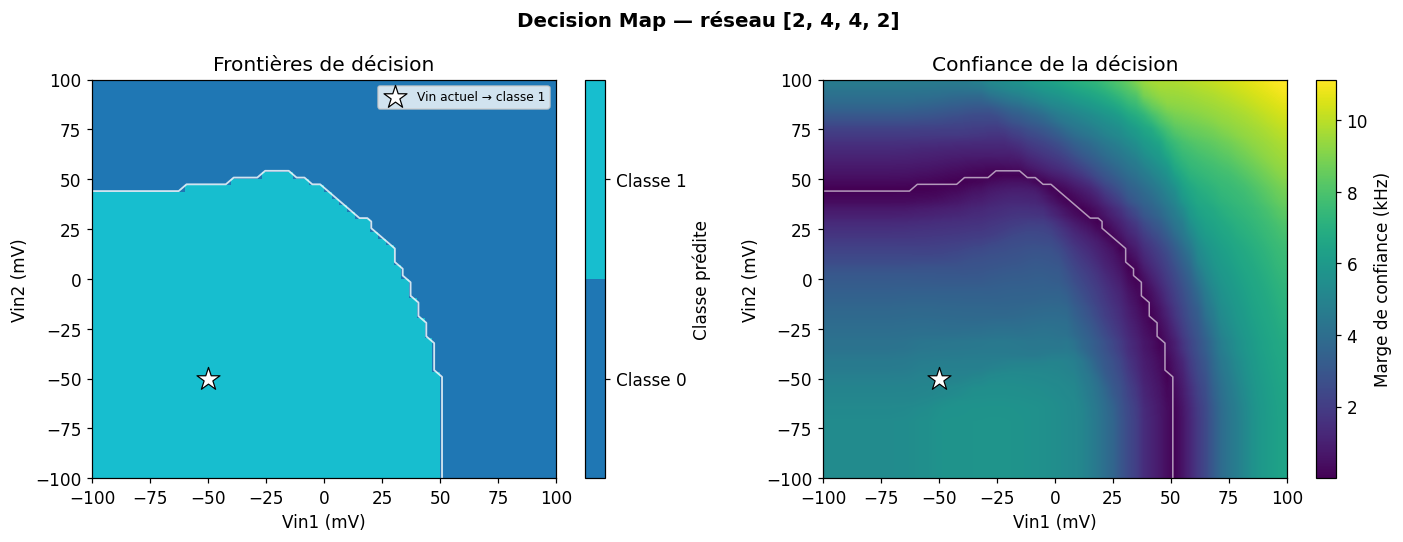


── Surface couverte par classe ──
  Classe 0 :  49.3% de la grille
  Classe 1 :  50.7% de la grille


In [44]:
## 6. Decision Map — carte de décision 2D

# ── Paramètres de la grille ───────────────────────────────────
VIN1_RANGE_MV = (-100, 100)   # plage de Vin1 en mV
VIN2_RANGE_MV = (-100, 100)   # plage de Vin2 en mV
N_POINTS      = 60            # résolution de la grille (N×N)

# ── Construction de la grille ─────────────────────────────────
v1_axis = np.linspace(VIN1_RANGE_MV[0] * 1e-3, VIN1_RANGE_MV[1] * 1e-3, N_POINTS)
v2_axis = np.linspace(VIN2_RANGE_MV[0] * 1e-3, VIN2_RANGE_MV[1] * 1e-3, N_POINTS)

class_grid    = np.zeros((N_POINTS, N_POINTS), dtype=int)
conf_grid     = np.zeros((N_POINTS, N_POINTS))   # "confiance" = max(Fout) - 2e_max(Fout)
fout_grid     = np.zeros((N_POINTS, N_POINTS, layer_sizes[-1]))

print(f"Calcul de la decision map ({N_POINTS}×{N_POINTS} = {N_POINTS**2} points)...")

for ii, v1 in enumerate(v1_axis):
    for jj, v2 in enumerate(v2_axis):
        Vin_local = np.array([v1, v2])
        F_local   = np.array([float(input_f_of_v(v)) for v in Vin_local])
        for cfg in layers_config:
            F_local, _, _ = layer_forward(F_local,
                                          np.asarray(cfg['signs'],  int),
                                          np.asarray(cfg['widths'], float))
        fout_grid[ii, jj] = F_local
        pred = int(np.argmax(F_local))
        class_grid[ii, jj] = pred
        # marge de confiance (différence entre les deux plus grandes fréquences)
        sorted_f = np.sort(F_local)
        conf_grid[ii, jj] = (sorted_f[-1] - sorted_f[-2]) if len(sorted_f) > 1 else sorted_f[-1]

print("✓ Terminé.")

# ── Visualisation ─────────────────────────────────────────────
n_classes = layer_sizes[-1]
cmap_dec  = plt.cm.get_cmap('tab10', n_classes)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Decision Map — réseau " + str(layer_sizes), fontsize=13, fontweight='bold')

# — Carte des classes —
ax = axes[0]
im = ax.imshow(
    class_grid.T,
    origin='lower',
    extent=[VIN1_RANGE_MV[0], VIN1_RANGE_MV[1],
            VIN2_RANGE_MV[0], VIN2_RANGE_MV[1]],
    aspect='auto',
    cmap=cmap_dec,
    vmin=-0.5, vmax=n_classes - 0.5,
    interpolation='nearest'
)
cbar = plt.colorbar(im, ax=ax, ticks=range(n_classes))
cbar.set_label("Classe prédite")
cbar.set_ticklabels([f"Classe {k}" for k in range(n_classes)])

# Contours des frontières de décision
ax.contour(
    v1_axis * 1e3, v2_axis * 1e3, class_grid.T,
    levels=np.arange(-0.5, n_classes, 1),
    colors='white', linewidths=1.2, alpha=0.8
)

# Point correspondant à l'entrée courante définie dans §5
ax.scatter(Vin_V[0] * 1e3, Vin_V[1] * 1e3,
           marker='*', s=250, color='white', edgecolors='black',
           linewidths=0.8, zorder=5, label=f"Vin actuel → classe {int(np.argmax(history_F[-1]))}")
ax.set_xlabel("Vin1 (mV)")
ax.set_ylabel("Vin2 (mV)")
ax.set_title("Frontières de décision")
ax.legend(fontsize=8)
ax.grid(False)

# — Carte de confiance (marge entre les 2 premières classes) —
ax = axes[1]
im2 = ax.imshow(
    conf_grid.T * 1e-3,   # en kHz
    origin='lower',
    extent=[VIN1_RANGE_MV[0], VIN1_RANGE_MV[1],
            VIN2_RANGE_MV[0], VIN2_RANGE_MV[1]],
    aspect='auto',
    cmap='viridis',
    interpolation='bilinear'
)
plt.colorbar(im2, ax=ax, label="Marge de confiance (kHz)")

# Mêmes contours de classes en superposition
ax.contour(
    v1_axis * 1e3, v2_axis * 1e3, class_grid.T,
    levels=np.arange(-0.5, n_classes, 1),
    colors='white', linewidths=1.0, alpha=0.6
)
ax.scatter(Vin_V[0] * 1e3, Vin_V[1] * 1e3,
           marker='*', s=250, color='white', edgecolors='black', linewidths=0.8, zorder=5)
ax.set_xlabel("Vin1 (mV)")
ax.set_ylabel("Vin2 (mV)")
ax.set_title("Confiance de la décision")
ax.grid(False)

plt.tight_layout()
plt.show()

# ── Résumé par classe ─────────────────────────────────────────
print("\n── Surface couverte par classe ──")
total = N_POINTS ** 2
for k in range(n_classes):
    pct = 100 * np.sum(class_grid == k) / total
    print(f"  Classe {k} : {pct:5.1f}% de la grille")